# Predicting US Flight Cancellations: Traditional ML vs Deep Learning
**Part 1 of 3: Setup, data loading, EDA and the temporal split**

**Problem.** Flight cancellations are far more disruptive to passengers than delays. A passenger who knows days ahead that a flight is at elevated risk can rebook, and an airport can plan staffing. This notebook builds a binary classifier (`Cancelled` = 1 or 0) that uses **only information known when the schedule is published**.

**Data.** US Bureau of Transportation Statistics (BTS) On-Time Performance data (Reporting Carrier), Jan 2023 to Dec 2024. A 5% random sample was drawn per month after computing congestion features on the full data; `build_dataset.py` documents this process.

**Why the US data?** Open, flight-level performance data for African carriers is not available, and that gap is itself a finding of this project. The methodology here is what African aviation authorities could replicate if comparable data were published. Transferability limits are discussed in the report.

**Notebook map:** Part 1 (this notebook): setup, EDA, split. Part 2: preprocessing and feature engineering, traditional ML. Part 3: deep learning, evaluation, error analysis.

## 1. Setup and reproducibility
All randomness is controlled from one seed. TensorFlow's `set_random_seed` seeds Python, NumPy and TensorFlow together; the guard lets the notebook still run if TensorFlow is missing. Kaggle already includes every library used here, so `requirements.txt` in the repository is generated from these imports.

In [1]:
import os, glob, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
    except ImportError:
        pass

set_seeds()
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 2. Loading the data
The sampled dataset was attached as a Kaggle input. The cell finds the file automatically so the notebook does not depend on a hard-coded dataset name, and reads the build log to report the size of the **raw** data before sampling, which is what the 20,000-row requirement refers to.

In [4]:
DATA_GLOB = os.environ.get("DATA_GLOB", "/kaggle/input/**/*.csv")
LOG_GLOB = DATA_GLOB.replace("*.csv", "build_log.json")

data_files = glob.glob(DATA_GLOB, recursive=True)
assert len(data_files) == 1, f"Expected exactly one data file, found: {data_files}"
df = pd.read_csv(data_files[0], parse_dates=["FlightDate"])

log_files = glob.glob(LOG_GLOB, recursive=True)
if log_files:
    with open(log_files[0]) as f:
        build_log = json.load(f)
    print(f"Raw rows (Jan 2023 - Dec 2024):   {build_log['raw_rows_main_period']:,}")
    print(f"After dropping diverted flights:  {build_log['rows_after_diverted_drop']:,}")
    print(f"Sampled rows ({build_log['sample_fraction']:.0%}):           {build_log['sampled_rows']:,}")
    print(f"Cancellation rate, full data:     {build_log['full_data_cancellation_rate']:.3%}")
    print(f"Cancellation rate, sample:        {build_log['sampled_cancellation_rate']:.3%}")
else:
    print("build_log.json not found; add it to the Kaggle dataset to report raw row counts.")

print("\nShape:", df.shape)
df.head()

Raw rows (Jan 2023 - Dec 2024):   13,926,960
After dropping diverted flights:  13,892,904
Sampled rows (5%):           694,648
Cancellation rate, full data:     1.326%
Cancellation rate, sample:        1.320%

Shape: (694648, 22)


,Year,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginState,Dest,DestState,...,Cancelled,CRSElapsedTime,Distance,DepHour,origin_hour_sched,origin_day_sched,dest_day_sched,route_day_sched,origin_cancel_rate_28d_lag7,carrier_cancel_rate_28d_lag7
0,2023,1,1,7,2023-01-01,F9,LAS,NV,PHL,PA,...,0,275.0,2176.0,1,1,483,222,5,0.037659,0.041955
1,2023,1,1,7,2023-01-01,AA,PNS,FL,DFW,TX,...,0,126.0,604.0,17,3,23,591,3,0.026012,0.016190
2,2023,1,1,7,2023-01-01,UA,LAX,CA,IAD,VA,...,0,283.0,2288.0,23,19,480,111,6,0.020162,0.023679
3,2023,1,1,7,2023-01-01,OO,ASE,CO,ATL,GA,...,0,206.0,1304.0,13,5,32,701,1,0.093578,0.041818
4,2023,1,1,7,2023-01-01,WN,DAL,TX,LIT,AR,...,0,70.0,296.0,17,13,198,25,3,0.045598,0.060276


In [5]:
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T

Year                                     int64
Month                                    int64
DayofMonth                               int64
DayOfWeek                                int64
FlightDate                      datetime64[ns]
Reporting_Airline                       object
Origin                                  object
OriginState                             object
Dest                                    object
DestState                               object
CRSDepTime                               int64
CRSArrTime                               int64
Cancelled                                int64
CRSElapsedTime                         float64
Distance                               float64
DepHour                                  int64
origin_hour_sched                        int64
origin_day_sched                         int64
dest_day_sched                           int64
route_day_sched                          int64
origin_cancel_rate_28d_lag7            float64
carrier_cance

,count,mean,min,25%,50%,75%,max,std
Year,694648.0,2023.508286,2023.0,2023.0,2024.0,2024.0,2024.0,0.499932
Month,694648.0,6.585566,1.0,4.0,7.0,10.0,12.0,3.403302
DayofMonth,694648.0,15.764528,1.0,8.0,16.0,23.0,31.0,8.786153
DayOfWeek,694648.0,3.98294,1.0,2.0,4.0,6.0,7.0,2.008058
FlightDate,694648,2024-01-05 19:08:19.922838784,2023-01-01 00:00:00,2023-07-08 00:00:00,2024-01-07 00:00:00,2024-07-08 00:00:00,2024-12-31 00:00:00,NaN
CRSDepTime,694648.0,1329.789014,1.0,909.0,1322.0,1740.0,2359.0,494.440254
CRSArrTime,694648.0,1489.822926,1.0,1101.0,1516.0,1925.0,2359.0,522.547748
Cancelled,694648.0,0.013204,0.0,0.0,0.0,0.0,1.0,0.114147
CRSElapsedTime,694648.0,146.340649,21.0,93.0,130.0,177.0,693.0,72.698978
Distance,694648.0,833.673653,21.0,399.0,680.0,1068.0,5095.0,597.430827


**Interpretation.** *Write your own notes here: how many rows and columns, which columns have missing values and why (for example, trailing rates are undefined for an airport or carrier with no history in the window), and what the raw-to-sample ratio means for the study.*

## 3. Exploratory data analysis

### 3.1 Class balance
Cancellations are rare, so a model that predicts "not cancelled" for every flight would score high accuracy while being useless. This is why the project reports precision, recall, PR-AUC and ROC-AUC rather than accuracy alone, and why the validation and test sets keep the natural class balance.

Cancelled
Not cancelled    685476
Cancelled          9172
Name: count, dtype: int64

Cancellation rate: 1.320%   |   imbalance ratio: 1 : 75


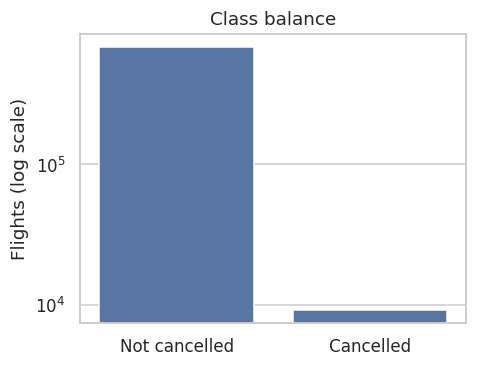

In [6]:
counts = df["Cancelled"].value_counts().sort_index()
rate = df["Cancelled"].mean()
print(counts.rename({0: "Not cancelled", 1: "Cancelled"}))
print(f"\nCancellation rate: {rate:.3%}   |   imbalance ratio: 1 : {(1 - rate) / rate:.0f}")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=["Not cancelled", "Cancelled"], y=counts.values, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Flights (log scale)"); ax.set_title("Class balance")
plt.tight_layout(); plt.show()

### 3.2 Cancellations over time
Daily cancellation rates show whether cancellations are steady or clustered in events. Clusters matter for the split design and for error analysis later: a model trained mostly on calm days will struggle on event days. The shaded and dashed markers show the CrowdStrike outage (19 to 22 July 2024, which falls in the validation period) and the landfalls of Hurricanes Helene and Milton. *Verify these event dates against a cited source before using them in the report.*

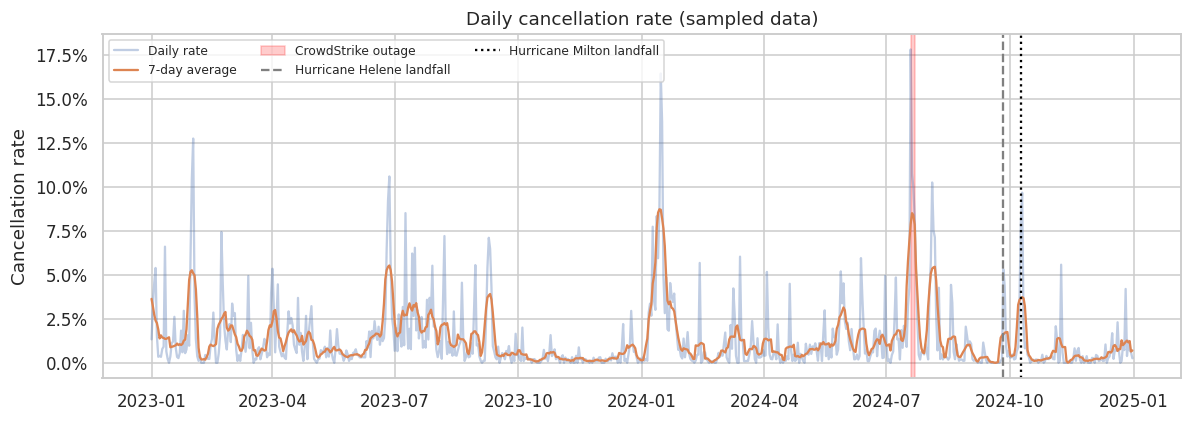

Ten highest-rate days:


,rate,flights,rate_7d
FlightDate,,,
2024-07-19,0.178145,1089,0.078882
2024-01-15,0.164474,912,0.087022
2024-01-16,0.136986,803,0.082072
2023-02-01,0.127485,855,0.050907
2024-07-20,0.107582,976,0.085070
2023-06-27,0.105946,925,0.055329
2023-01-31,0.104839,868,0.052602
2024-08-04,0.102515,1034,0.053543
2024-07-21,0.099718,1063,0.083907


In [7]:
daily = df.groupby("FlightDate")["Cancelled"].agg(rate="mean", flights="size")
daily["rate_7d"] = daily["rate"].rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["rate"], alpha=0.35, label="Daily rate")
ax.plot(daily.index, daily["rate_7d"], label="7-day average")
ax.axvspan(pd.Timestamp("2024-07-19"), pd.Timestamp("2024-07-22"), color="red", alpha=0.2, label="CrowdStrike outage")
ax.axvline(pd.Timestamp("2024-09-26"), color="gray", ls="--", label="Hurricane Helene landfall")
ax.axvline(pd.Timestamp("2024-10-09"), color="black", ls=":", label="Hurricane Milton landfall")
ax.set_ylabel("Cancellation rate"); ax.set_title("Daily cancellation rate (sampled data)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

print("Ten highest-rate days:")
daily.sort_values("rate", ascending=False).head(10)

**Interpretation.** *Which days or periods stand out? Do they match known events (winter storms, the outage, hurricanes)? What does that imply for how predictable cancellations are from schedule-time information alone?*

### 3.3 Calendar patterns
Month, day of week and scheduled departure hour are the cheapest schedule-time features. These plots show whether they carry any signal and motivate the cyclical encoding of hour in Part 2.

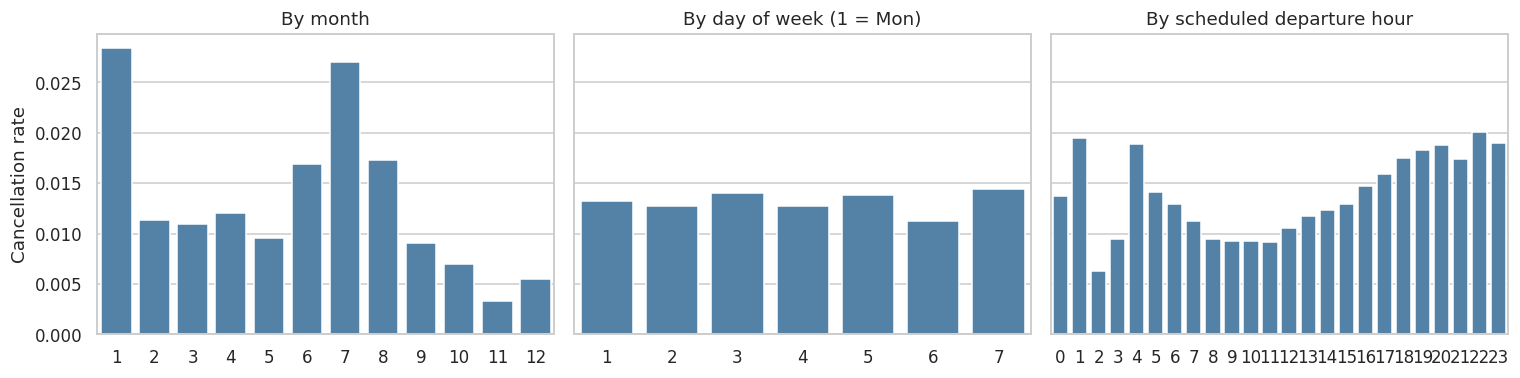

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (col, title) in zip(axes, [("Month", "By month"), ("DayOfWeek", "By day of week (1 = Mon)"), ("DepHour", "By scheduled departure hour")]):
    r = df.groupby(col)["Cancelled"].mean()
    sns.barplot(x=r.index, y=r.values, ax=ax, color="steelblue")
    ax.set_title(title); ax.set_xlabel(""); 
axes[0].set_ylabel("Cancellation rate")
plt.tight_layout(); plt.show()

### 3.4 Carriers and airports
Rates are noisy for small groups, particularly in a 5% sample, so groups below a minimum flight count are excluded from the airport view. Large differences between carriers or airports justify using them as features, and the spread across airports connects to the equity question in the report (do smaller airports, which resemble many African airports, behave differently?).

Carriers:


,flights,cancelled,rate
Reporting_Airline,,,
WN,142944,1368,0.009570
DL,99497,946,0.009508
AA,95893,1244,0.012973
UA,74040,1158,0.015640
OO,71201,829,0.011643
YX,29885,660,0.022085
NK,26214,479,0.018273
B6,25557,446,0.017451
MQ,25178,327,0.012988


Airports with at least 1,000 sampled departures: 99 (of 354 total)


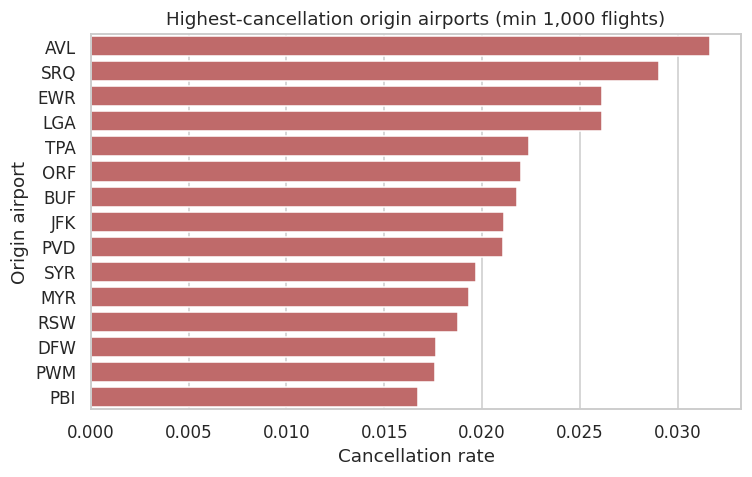

In [9]:
carrier = (df.groupby("Reporting_Airline")["Cancelled"]
             .agg(flights="size", cancelled="sum", rate="mean")
             .sort_values("flights", ascending=False))
print("Carriers:")
display(carrier)

MIN_FLIGHTS = 1000
origin = (df.groupby("Origin")["Cancelled"].agg(flights="size", rate="mean"))
origin = origin[origin["flights"] >= MIN_FLIGHTS]
print(f"Airports with at least {MIN_FLIGHTS:,} sampled departures: {len(origin)} "
      f"(of {df['Origin'].nunique()} total)")

top = origin.sort_values("rate", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top["rate"], y=top.index, ax=ax, color="indianred")
ax.set_xlabel("Cancellation rate"); ax.set_ylabel("Origin airport")
ax.set_title(f"Highest-cancellation origin airports (min {MIN_FLIGHTS:,} flights)")
plt.tight_layout(); plt.show()

**Interpretation.** *Which carriers and airports are over- or under-represented in cancellations? Are the highest-rate airports large hubs or smaller airports? Is the carrier effect plausibly operational (network structure, regional partners) or an artefact of how BTS defines reporting carriers?*

### 3.5 Engineered schedule-time features
The congestion counts and trailing cancellation rates were created in `build_dataset.py`. Binning each into deciles and plotting the cancellation rate per bin is a quick empirical check on whether they carry signal. This is the first piece of evidence for the feature-engineering section of the report; the with/without comparison experiment comes in Part 2.

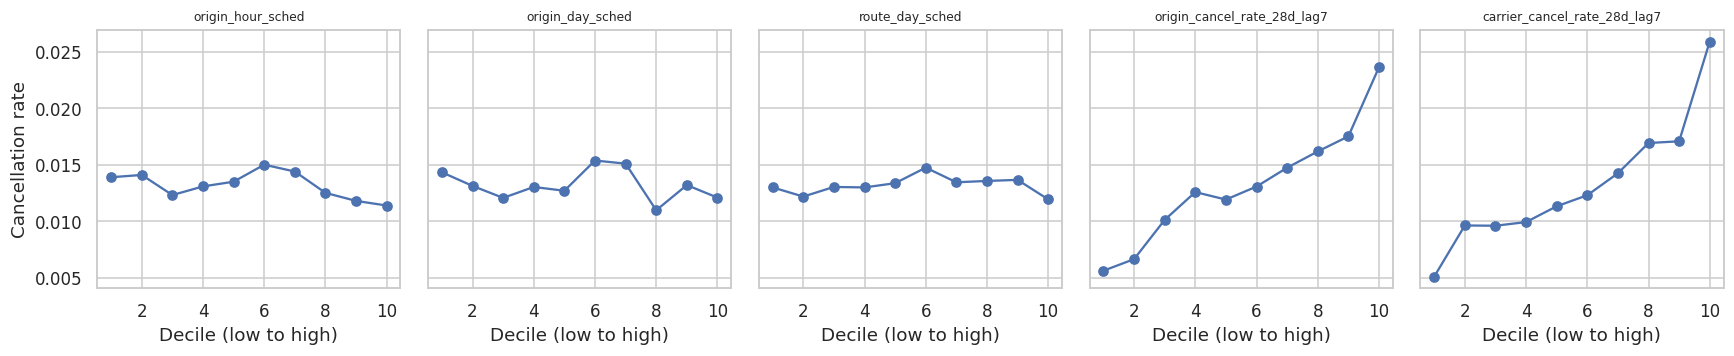

Correlation with target (point-biserial via Pearson):


carrier_cancel_rate_28d_lag7    0.042063
origin_cancel_rate_28d_lag7     0.039985
route_day_sched                -0.000343
CRSElapsedTime                 -0.002342
origin_day_sched               -0.002763
origin_hour_sched              -0.005738
Distance                       -0.006135
Name: Cancelled, dtype: float64

In [10]:
eng_features = ["origin_hour_sched", "origin_day_sched", "route_day_sched",
                "origin_cancel_rate_28d_lag7", "carrier_cancel_rate_28d_lag7"]

fig, axes = plt.subplots(1, len(eng_features), figsize=(16, 3.4), sharey=True)
for ax, feat in zip(axes, eng_features):
    bins = pd.qcut(df[feat], q=10, duplicates="drop")
    r = df.groupby(bins, observed=True)["Cancelled"].mean().reset_index(drop=True)
    ax.plot(range(1, len(r) + 1), r.values, marker="o")
    ax.set_title(feat, fontsize=8); ax.set_xlabel("Decile (low to high)")
axes[0].set_ylabel("Cancellation rate")
plt.tight_layout(); plt.show()

print("Correlation with target (point-biserial via Pearson):")
df[eng_features + ["Distance", "CRSElapsedTime", "Cancelled"]].corr()["Cancelled"].drop("Cancelled").sort_values(ascending=False)

**Interpretation.** *Which features show a clear monotonic relationship with cancellation and which look flat? Weak linear correlation does not rule out a useful non-linear effect, which is one reason tree-based models are compared against logistic regression in Part 2.*

## 4. Leakage audit and temporal split

### 4.1 Leakage audit
Prediction is framed as happening **at schedule publication, days before departure**. Any column recorded during or after the flight would let the model cheat, so the cell below fails loudly if one is present.

In [11]:
FORBIDDEN = {"DepTime", "DepDelay", "ArrTime", "ArrDelay", "TaxiOut", "TaxiIn", "WheelsOff", "WheelsOn",
             "AirTime", "ActualElapsedTime", "CancellationCode", "CarrierDelay", "WeatherDelay",
             "NASDelay", "SecurityDelay", "LateAircraftDelay"}
leaked = FORBIDDEN & set(df.columns)
assert not leaked, f"Leaky columns present: {leaked}"
print("No post-departure columns found. Available columns:")
print(list(df.columns))

No post-departure columns found. Available columns:
['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'Origin', 'OriginState', 'Dest', 'DestState', 'CRSDepTime', 'CRSArrTime', 'Cancelled', 'CRSElapsedTime', 'Distance', 'DepHour', 'origin_hour_sched', 'origin_day_sched', 'dest_day_sched', 'route_day_sched', 'origin_cancel_rate_28d_lag7', 'carrier_cancel_rate_28d_lag7']


### 4.2 Temporal split
A random split would let the model see flights from the same day or week as the test flights, which overstates performance relative to real use. Instead, the data is split by date: **train** Jan 2023 to Jun 2024, **validation** Jul to Sep 2024, **test** Oct to Dec 2024. Validation and test keep the natural class balance; any resampling is applied to the training set only. The test set is touched once, at the end.

In [12]:
TRAIN_END = pd.Timestamp("2024-06-30")
VAL_START, VAL_END = pd.Timestamp("2024-07-01"), pd.Timestamp("2024-09-30")
TEST_START = pd.Timestamp("2024-10-01")

train = df[df["FlightDate"] <= TRAIN_END].copy()
val = df[(df["FlightDate"] >= VAL_START) & (df["FlightDate"] <= VAL_END)].copy()
test = df[df["FlightDate"] >= TEST_START].copy()

assert len(train) + len(val) + len(test) == len(df)
assert train["FlightDate"].max() < val["FlightDate"].min() <= val["FlightDate"].max() < test["FlightDate"].min()

summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "from": [d["FlightDate"].min().date() for d in (train, val, test)],
    "to": [d["FlightDate"].max().date() for d in (train, val, test)],
    "rows": [len(d) for d in (train, val, test)],
    "cancelled": [int(d["Cancelled"].sum()) for d in (train, val, test)],
    "cancel_rate": [d["Cancelled"].mean() for d in (train, val, test)],
})
summary["share_of_data"] = summary["rows"] / summary["rows"].sum()
summary.style.format({"cancel_rate": "{:.3%}", "share_of_data": "{:.1%}"})

,split,from,to,rows,cancelled,cancel_rate,share_of_data
0,train,2023-01-01,2024-06-30,514176,6833,1.329%,74.0%
1,validation,2024-07-01,2024-09-30,91555,1687,1.843%,13.2%
2,test,2024-10-01,2024-12-31,88917,652,0.733%,12.8%


### 4.3 Event window and unseen categories
The CrowdStrike outage produced an unusual spike inside the validation period. Tuning hyperparameters on a window dominated by a one-off event could mislead model selection, so the validation set is flagged and results are reported with and without those four days. Separately, because the split is temporal, validation or test may contain airports, routes or carriers never seen in training; the encoding strategy in Part 2 must handle that, so the size of the problem is measured here.

In [13]:
CS_START, CS_END = pd.Timestamp("2024-07-19"), pd.Timestamp("2024-07-22")
val["crowdstrike_window"] = val["FlightDate"].between(CS_START, CS_END)
print(f"Validation cancellation rate inside the window:  {val.loc[val.crowdstrike_window, 'Cancelled'].mean():.3%} "
      f"({val.crowdstrike_window.sum():,} flights)")
print(f"Validation cancellation rate outside the window: {val.loc[~val.crowdstrike_window, 'Cancelled'].mean():.3%}")
val_clean = val[~val["crowdstrike_window"]]

print("\nShare of rows with a category unseen in training:")
for col in ["Reporting_Airline", "Origin", "Dest"]:
    seen = set(train[col].unique())
    print(f"  {col:18s} validation: {(~val[col].isin(seen)).mean():.2%}   test: {(~test[col].isin(seen)).mean():.2%}")
train["route"] = train["Origin"] + "-" + train["Dest"]
val["route"] = val["Origin"] + "-" + val["Dest"]
test["route"] = test["Origin"] + "-" + test["Dest"]
seen_routes = set(train["route"].unique())
print(f"  {'route':18s} validation: {(~val['route'].isin(seen_routes)).mean():.2%}   test: {(~test['route'].isin(seen_routes)).mean():.2%}")

Validation cancellation rate inside the window:  11.720% (4,249 flights)
Validation cancellation rate outside the window: 1.362%

Share of rows with a category unseen in training:
  Reporting_Airline  validation: 0.00%   test: 0.00%
  Origin             validation: 0.00%   test: 0.01%
  Dest               validation: 0.00%   test: 0.01%
  route              validation: 0.24%   test: 0.31%


## Part 1 summary
*Write three or four sentences in your own words: the class imbalance, what the time series and calendar plots revealed, which engineered features look informative, and how large the unseen-category problem is. These notes feed directly into the Methodology and Discussion sections of the report.*

**Next (Part 2):** preprocessing pipeline, feature engineering experiments (with vs without engineered features), and the traditional ML models with hyperparameter tuning and experiment logging.